<a href="https://colab.research.google.com/github/renatobdo/doutorado/blob/main/04_comparacao_a90_a91_sim_2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Título e objetivo

# Comparação entre óbitos por dengue (A90) e dengue hemorrágica (A91)

Este notebook compara os óbitos cuja causa básica foi dengue (A90) com aqueles cuja causa básica foi dengue hemorrágica (A91).

São analisados:

- distribuição dos óbitos por tipo de dengue;
- perfil demográfico;
- causas e condições associadas;
- frequência das condições em cada grupo;
- diferenças absolutas e relativas;
- condições mais características de cada grupo.

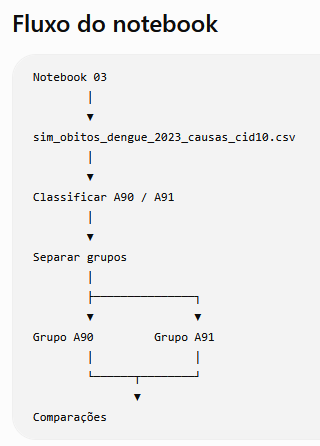

1 - Importação das bibliotecas

In [ ]:
import os
import pandas as pd
import numpy as np


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


2-Carregamento

3. Definição dos caminhos

In [ ]:
BASE_DIR = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag"
)

CAMINHO_OBITOS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_reduzido.csv"
)

CAMINHO_CAUSAS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_causas_cid10.csv"
)

CAMINHO_SAIDA_RESUMO = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_resumo_a90_a91.csv"
)

CAMINHO_SAIDA_COMPARACAO = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_comparacao_causas_a90_a91.csv"
)

CAMINHO_SAIDA_DEMOGRAFICO = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_perfil_demografico_a90_a91.csv"
)

4. Verificação dos arquivos

In [ ]:
arquivos_obrigatorios = [
    CAMINHO_OBITOS,
    CAMINHO_CAUSAS
]

for caminho in arquivos_obrigatorios:
    if not os.path.exists(caminho):
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho}"
        )

print("Todos os arquivos de entrada foram encontrados.")

5. Carregamento das bases

In [ ]:
df_obitos = pd.read_csv(
    CAMINHO_OBITOS,
    encoding="utf-8-sig",
    dtype="string"
)

df_causas = pd.read_csv(
    CAMINHO_CAUSAS,
    encoding="utf-8-sig",
    dtype="string"
)

print("Base de óbitos:")
print(df_obitos.shape)

print("\nBase de causas:")
print(df_causas.shape)

6. Padronização do identificador

O ideal é que o arquivo reduzido produzido pelo notebook 01 já tenha ID_REGISTRO. Caso não tenha, criamos o identificador pela ordem das linhas.

In [ ]:
df_obitos = df_obitos.reset_index(drop=True).copy()

if "ID_REGISTRO" not in df_obitos.columns:
    df_obitos.insert(
        0,
        "ID_REGISTRO",
        df_obitos.index + 1
    )
else:
    df_obitos["ID_REGISTRO"] = pd.to_numeric(
        df_obitos["ID_REGISTRO"],
        errors="raise"
    ).astype("int64")

Na base de causas:

In [ ]:
df_causas["ID_REGISTRO"] = pd.to_numeric(
    df_causas["ID_REGISTRO"],
    errors="raise"
).astype("int64")

Validações:

In [ ]:
if not df_obitos["ID_REGISTRO"].is_unique:
    raise ValueError(
        "ID_REGISTRO não é único na base de óbitos."
    )

ids_obitos = set(df_obitos["ID_REGISTRO"])
ids_causas = set(df_causas["ID_REGISTRO"])

ids_sem_correspondencia = ids_causas - ids_obitos

print(
    "IDs da base de causas sem correspondência na base de óbitos:",
    len(ids_sem_correspondencia)
)

O esperado é: 0

7. Normalização da causa básica

In [ ]:
df_obitos["CAUSABAS_NORMALIZADA"] = (
    df_obitos["CAUSABAS"]
    .astype("string")
    .str.upper()
    .str.strip()
    .str.replace("*", "", regex=False)
    .str.replace(".", "", regex=False)
)

8. Classificação entre A90 e A91

In [ ]:
condicoes = [
    df_obitos["CAUSABAS_NORMALIZADA"].str.startswith(
        "A90",
        na=False
    ),
    df_obitos["CAUSABAS_NORMALIZADA"].str.startswith(
        "A91",
        na=False
    )
]

classificacoes = [
    "Dengue (A90)",
    "Dengue hemorrágica (A91)"
]

df_obitos["TIPO_DENGUE"] = np.select(
    condicoes,
    classificacoes,
    default="Não classificado"
)

Confira:

In [ ]:
df_obitos[
    [
        "ID_REGISTRO",
        "CAUSABAS",
        "CAUSABAS_NORMALIZADA",
        "TIPO_DENGUE"
    ]
].head(20)

Verifique registros não classificados:

In [ ]:
df_nao_classificados = df_obitos[
    df_obitos["TIPO_DENGUE"] == "Não classificado"
]

print(
    "Registros não classificados:",
    len(df_nao_classificados)
)

if len(df_nao_classificados) > 0:
    display(
        df_nao_classificados[
            [
                "ID_REGISTRO",
                "CAUSABAS",
                "CAUSABAS_NORMALIZADA"
            ]
        ].head(20)
    )

9. Resumo dos óbitos por tipo

In [ ]:
resumo_por_tipo = (
    df_obitos[
        df_obitos["TIPO_DENGUE"] != "Não classificado"
    ]
    .groupby("TIPO_DENGUE")
    .agg(
        total_obitos=("ID_REGISTRO", "nunique")
    )
    .reset_index()
)

In [ ]:
total_obitos_classificados = (
    resumo_por_tipo["total_obitos"].sum()
)

resumo_por_tipo["percentual"] = (
    resumo_por_tipo["total_obitos"]
    / total_obitos_classificados
    * 100
).round(2)

resumo_por_tipo